# AI-Assisted Disaster Relief Decision Support: Reproducible Research Audit

This notebook explains and recomputes the completed continuation. It preserves the historical Track A benchmark, executes the Phase50 observable-pixel analysis from saved real pixels, audits multi-hazard support, and evaluates explicitly synthetic allocation scenarios. It does **not** establish a fully validated operational multi-hazard system. Historical reports, newly executed observations, simulation and blocked work have separate evidence labels.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
import numpy as np, pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'research': ROOT = ROOT.parent
assert (ROOT/'master_openfema_40plus.xlsx').exists()
os.environ['MPLCONFIGDIR'] = str(ROOT/'work/matplotlib')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
sys.path.insert(0, str(ROOT/'analysis'))
R = ROOT/'research'
print('Python', sys.version.split()[0], 'repository', ROOT)

Fontconfig error: No writable cache directories


Python 3.12.14 repository /workspace/ML-thesis/work/archive-smoke/ML-thesis


## 1. Preserve and inspect the original data

The workbook has one row per FEMA identifier. One negative net-obligation target is clamped to zero by the original band function. Bands are lower-inclusive, upper-exclusive: [0,100K), [100K,1M), [1M,50M), [50M,200M), [200M,500M), [500M,∞). These are accounting obligations, not independently observed needs. The original workbook is never rewritten.

,incidentType,records,fiscal_years,states,earliest_fy,latest_fy
0,Biological,59,2,56,2020,2021
1,Coastal Storm,6,4,4,2012,2022
2,Dam/Levee Break,1,1,1,2020,2020
3,Earthquake,8,6,6,2010,2023
4,Fire,33,14,10,2011,2024
5,Flood,198,15,45,2010,2024
6,Freezing,1,1,1,2013,2013
7,Hurricane,108,13,29,2010,2024
8,Mud/Landslide,9,8,6,2013,2024
9,Other,2,2,2,2013,2021


Negative original targets: 1


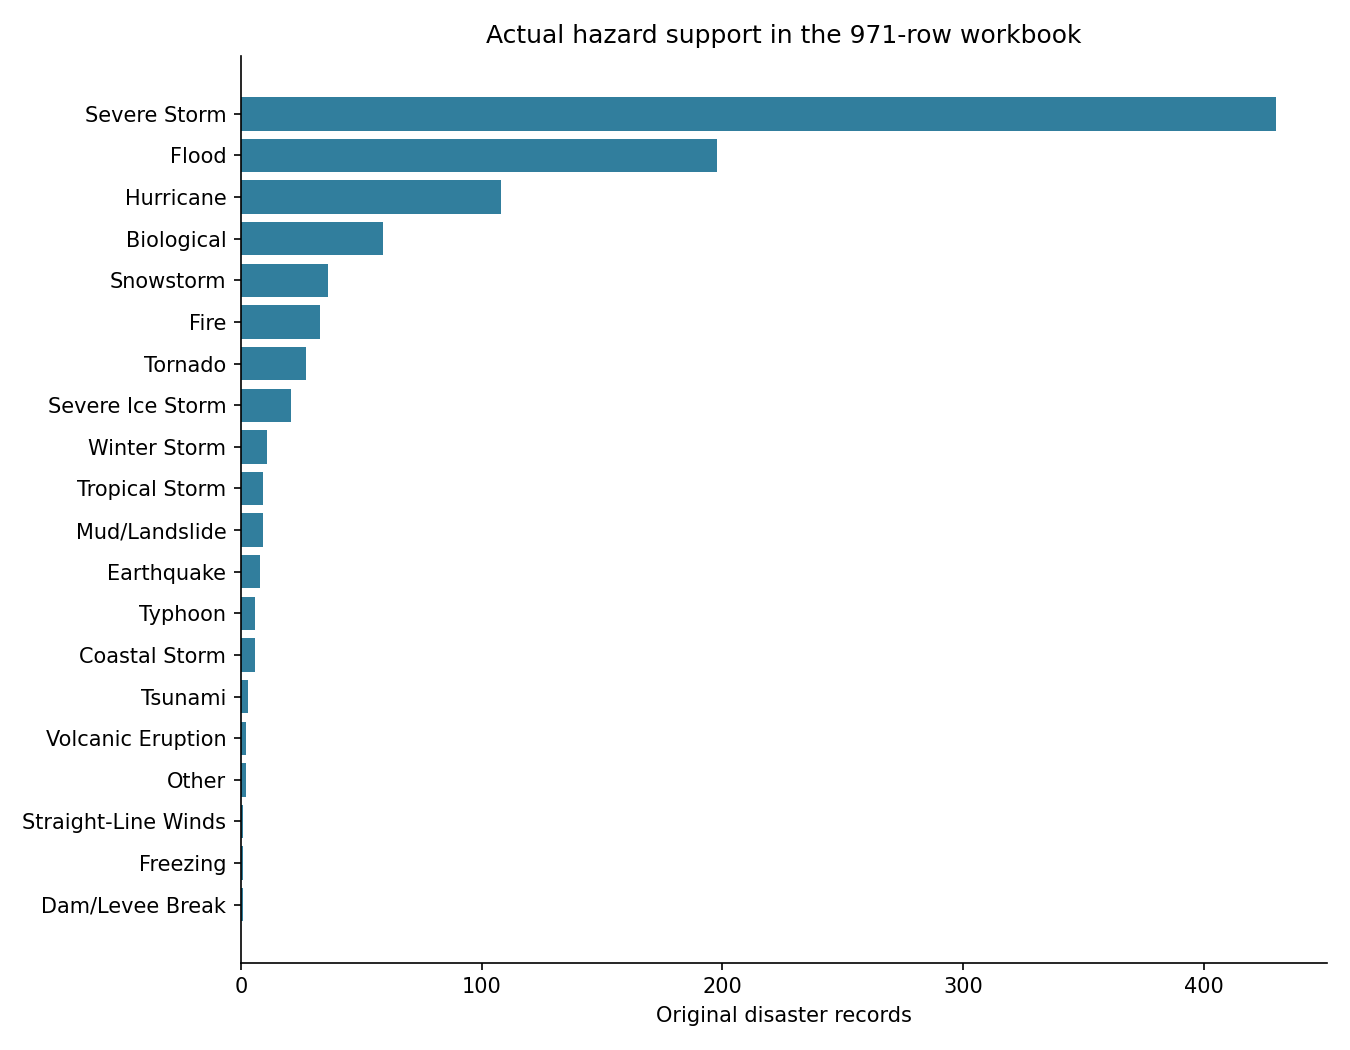

In [2]:
master=pd.read_excel(ROOT/'master_openfema_40plus.xlsx')
assert len(master)==971 and master.disasterNumber.is_unique
assert (master.incidentType!='Biological').sum()==912
display(pd.read_csv(R/'source_audit/hazard_inventory.csv'))
print('Negative original targets:', (master.totalObligatedFunding<0).sum())
display(Image(filename=str(R/'figures/hazard_support.png')))

## 2. Historical benchmark evidence and validation boundary

Track A reports 830/912 routing, MAE $5,014,819.0116 and R²0.88677657. The exact per-row artifact ZIP was recovered through the GitHub connector and byte-verified; the frozen metrics were then recomputed without training. Leave-fiscal-year-out excludes the held year but may use later years. It is not strict forward prediction. Existing CQR models are separate Track B models. The original specialist sources also contradict the handoff’s simplified statement that all three upper bands use medians: the accepted reconstruction includes a 50–200M hybrid and retained upper-band specialists.

In [3]:
metrics=pd.read_csv(ROOT/'FINAL_METRICS.csv')
display(metrics.query('study == "TrackA"')[['variant','metric','value','evidence']])
original=json.loads((R/'frozen_source_checksums.json').read_text())
assert all(hashlib.sha256((ROOT/x['path']).read_bytes()).hexdigest()==x['sha256'] for x in original)
print('Original source files unchanged:',len(original))

,variant,metric,value,evidence
0,frozen_original_stack,n,9.120000e+02,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
1,frozen_original_stack,MAE_USD,5.131360e+06,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
2,frozen_original_stack,RMSE_USD,6.471480e+07,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
3,frozen_original_stack,MedAE_USD,0.000000e+00,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
4,frozen_original_stack,R2,8.865627e-01,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
5,frozen_original_stack,log_MAE,1.537479e+00,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
6,frozen_original_stack,log_R2,6.620301e-01,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
7,frozen_original_stack,within20_positive,1.060172e-01,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
8,frozen_original_stack,within30_positive,1.747851e-01,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...
9,frozen_original_stack,within50_positive,2.779370e-01,RECOVERED HISTORICAL EXECUTION LOG; not per-ro...


Original source files unchanged: 342


In [4]:
from continuation_archive_recovery_audit import predictions, geometry_and_pixels
recomputed=predictions()
display(recomputed)
display(geometry_and_pixels())
display(pd.read_csv(R/'frozen_prediction_audit/router_confusion_matrix.csv'))

{'final': {'n': 912,
  'MAE_USD': 5014819.011614494,
  'RMSE_USD': 64653747.252143376,
  'MedAE_USD': 0.0,
  'R2': 0.8867765710842239,
  'log_MAE': 0.6951091508839052},
 'router_correct': 830,
 'router_total': 912,
 'router_accuracy': 0.9100877192982456,
 'balanced_accuracy': 0.8954508207273482,
 'macro_precision': 0.8672919106592576,
 'macro_recall': 0.8954508207273482,
 'macro_f1': 0.8785607328185371,
 'validation': 'fixed historical LFYO; not independent or prospective',
 'trained_models': 0,
 'bootstrap': {'repetitions': 2000,
  'seed': 20261117,
  'clusters': 'fiscal years, not independently verified physical events',
  'metric': 'accepted minus original MAE_USD',
  'observed': -116540.52726211677,
  'percentile95_lower': -301156.44293787266,
  'percentile95_upper': 28174.455236070015,
  'inference': 'descriptive fixed historical predictions; repeated model development; no independent confirmation or prospective validity'}}

{'original_sites': 187,
 'corrected_monthly_rows': 561,
 'corrected_comparison_rows': 374,
 'original_phase48_anchors_verified': 63,
 'phase50_integer_gain_matches': 67,
 'phase50_event_observability_matches': 67,
 'max_geometry_hausdorff_degrees': 0.0}

,actual_band,0-100K,100K-1M,1M-50M,50-200M,200-500M,500M+
0,0-100K,666,31,2,0,0,0
1,100K-1M,20,80,8,0,0,0
2,1M-50M,0,19,62,1,0,0
3,50-200M,0,0,0,12,1,0
4,200-500M,0,0,0,0,5,0
5,500M+,0,0,0,0,0,5


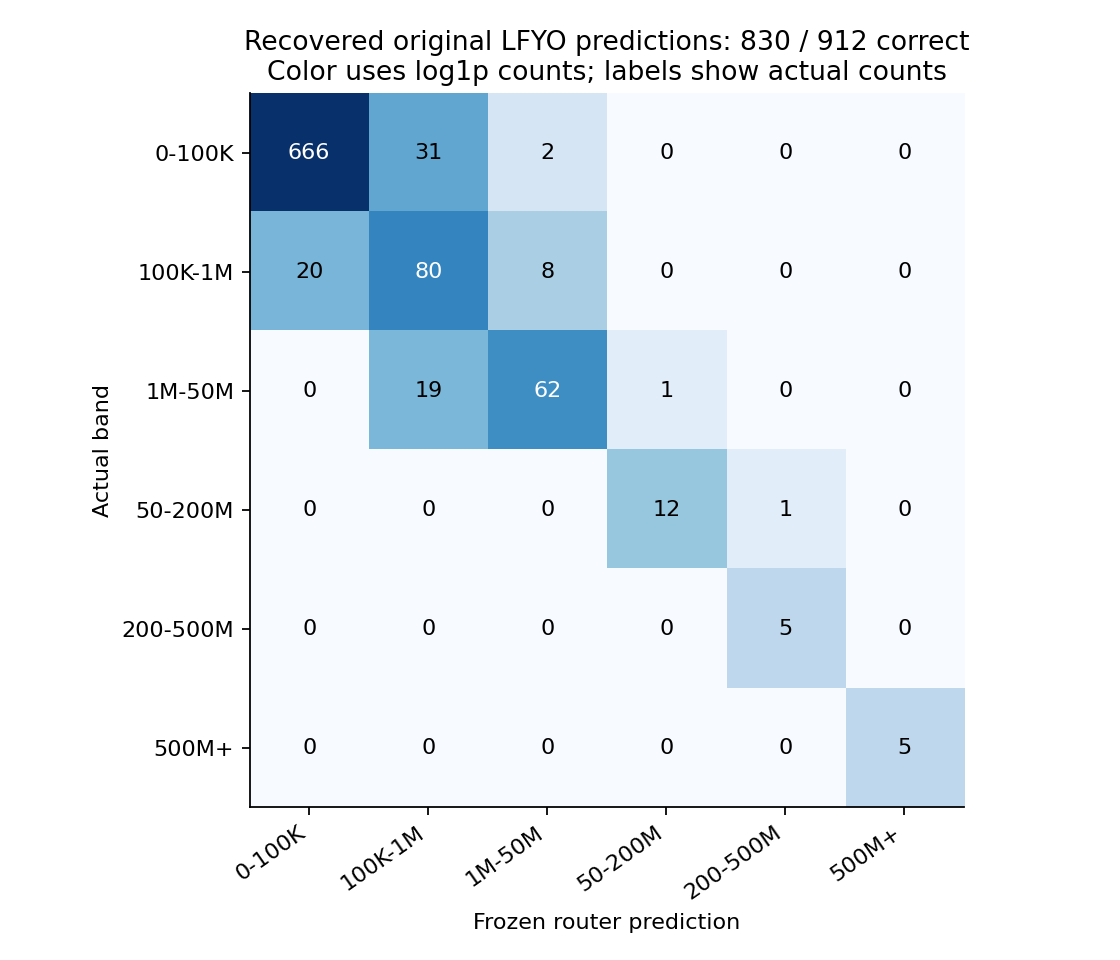

,variant,scope,group,n,MAE_USD,RMSE_USD,MedAE_USD,R2,log_MAE
0,frozen_stack_prediction,overall,all912,912,5.131360e+06,6.471480e+07,0.0,0.886563,1.537479
50,accepted_low_band_prediction,overall,all912,912,5.127644e+06,6.471478e+07,0.0,0.886563,0.696330
100,challenger_stack_prediction,overall,all912,912,5.014819e+06,6.465375e+07,0.0,0.886777,0.695109


In [5]:
display(Image(filename=str(R/'figures/frozen_router_confusion_matrix.png')))
display(pd.read_csv(R/'frozen_prediction_audit/monetary_metrics.csv').query('scope=="overall"'))

## 3. Phase50 question and mathematics

For fixed window $s$, let $C_s$ be the pixels with water/dry classifications at every date in both comparison arms. Class0 is unobserved. For pixel geodesic area $a_i$, $G_e=\sum_{i\in C_s}a_i1(x_{e,0}=1,x_{e,1}=2)$, and likewise $G_p$ for the placebo. The primary rate difference is $100(G_e-G_p)/\sum_{i\in C_s}a_i$. Loss and net change are also saved. Seasonal comparison is previous-month→incident-month in the event year versus the prior year. For2024, interannual comparison is2023→2024 versus2022→2023 at the same calendar month. No2021 imagery is mixed with the2022–24 edition. Tests cover the January boundary even though the final cohort has no comparison requiring that exclusion. Primary anchors and four added Minnesota sites are separate analyses.

In [6]:
from phase50_temporal_placebo import main as phase50_main
from unittest import TestLoader, TextTestRunner
import test_phase50_temporal_placebo
result=TextTestRunner(verbosity=1).run(TestLoader().loadTestsFromModule(test_phase50_temporal_placebo))
assert result.wasSuccessful()
print(json.loads((R/'phase50/summary.json').read_text())['provenance']['official_vs_master_date_discrepancies'])

.

.

.

.

.

.

----------------------------------------------------------------------
Ran 6 tests in 0.004s

OK


[{'disasterNumber': 4816, 'master_incident_start': '2024-08-22', 'official_current_incident_start': '2024-06-22', 'rule': 'official date used; source revision not authenticated as-of; log replay checked'}]


## 4. Recompute from saved real pixels without network

The saved cropped arrays include unobserved cells and exact window grids. Initial log-only checks were superseded after archive recovery: all187 original geometries match exactly, all67 integer water gains and event observation fractions match the corrected original CSVs, and the63 Phase48 anchor coordinates agree. The single DR4816 date mismatch was resolved against FEMA and original archive replay. Floating-point geodesic reconstruction tolerates1e-9km² after CSV coordinate round-trips; integer counts and historical match flags remain identical.

In [7]:
destination=ROOT/'work/notebook-phase50-reproduction'
run=subprocess.run([sys.executable,str(ROOT/'analysis/phase50_temporal_placebo.py'),'--offline-inputs',str(R/'phase50'),'--out',str(destination)],capture_output=True,text=True,timeout=120)
assert run.returncode==0,run.stderr[-2000:]
for name in ['site_temporal_comparisons.csv','aggregate_temporal_comparisons.csv','case_temporal_comparisons.csv','historical_log_replication.csv']:
    pd.testing.assert_frame_equal(pd.read_csv(R/'phase50'/name),pd.read_csv(destination/name),check_exact=False,rtol=1e-9,atol=1e-9)
print('Offline reproduction passed for all tables.')

Offline reproduction passed for all tables.


,scheme,group,sites,cases,event_gain_per100,placebo_gain_per100,delta_gain_per100
0,interannual,primary_63_anchors,17,11,0.117464,0.031095,0.086369
1,interannual,anchors_excluding_MN4722,17,11,0.117464,0.031095,0.086369
2,interannual,sensitivity_67_with_MN_extras,17,11,0.117464,0.031095,0.086369
3,interannual,MN4722_six_sites_only,0,0,NaN,NaN,NaN
24,seasonal,primary_63_anchors,44,27,0.080857,0.027784,0.053073
25,seasonal,anchors_excluding_MN4722,43,26,0.082883,0.028480,0.054403
26,seasonal,sensitivity_67_with_MN_extras,46,27,0.726199,0.038857,0.687342
27,seasonal,MN4722_six_sites_only,3,1,10.049488,0.189246,9.860242


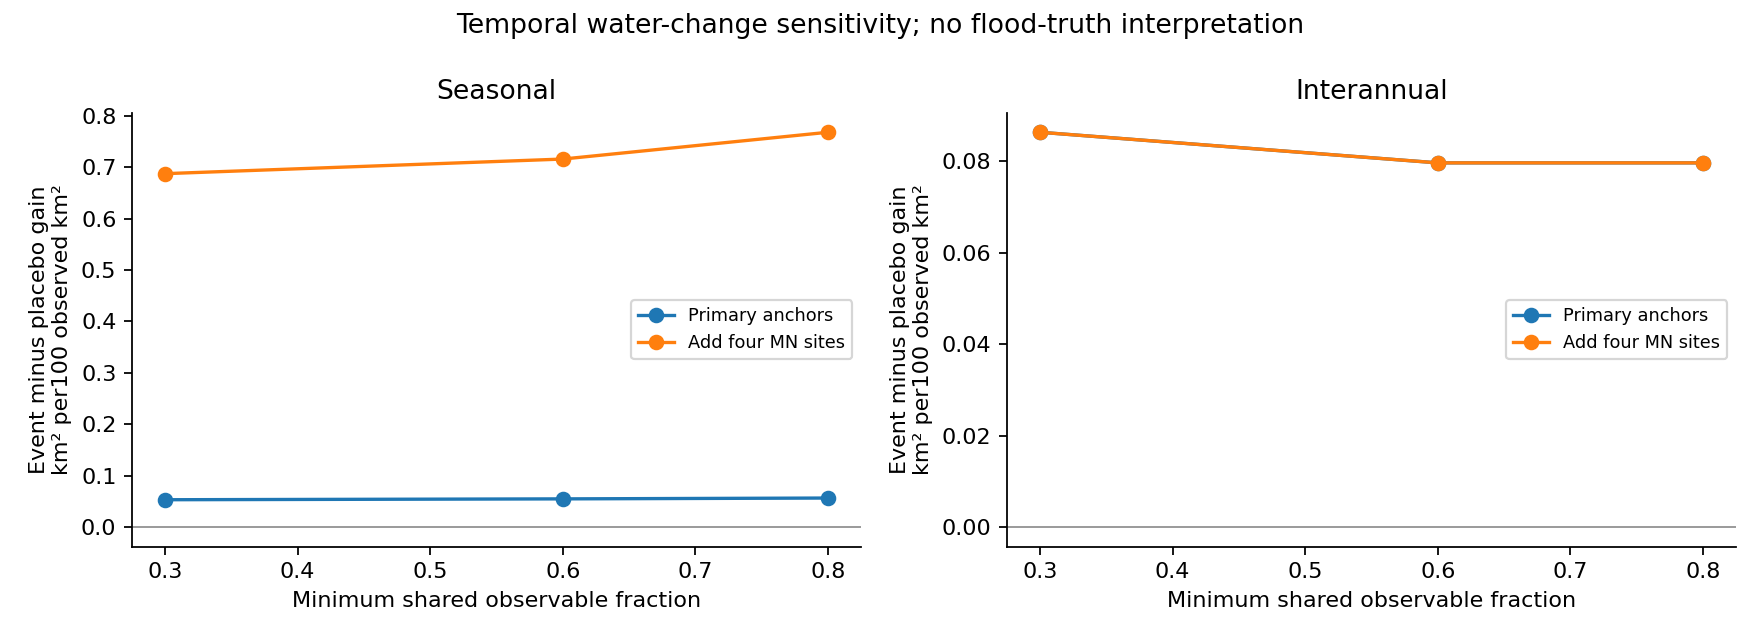

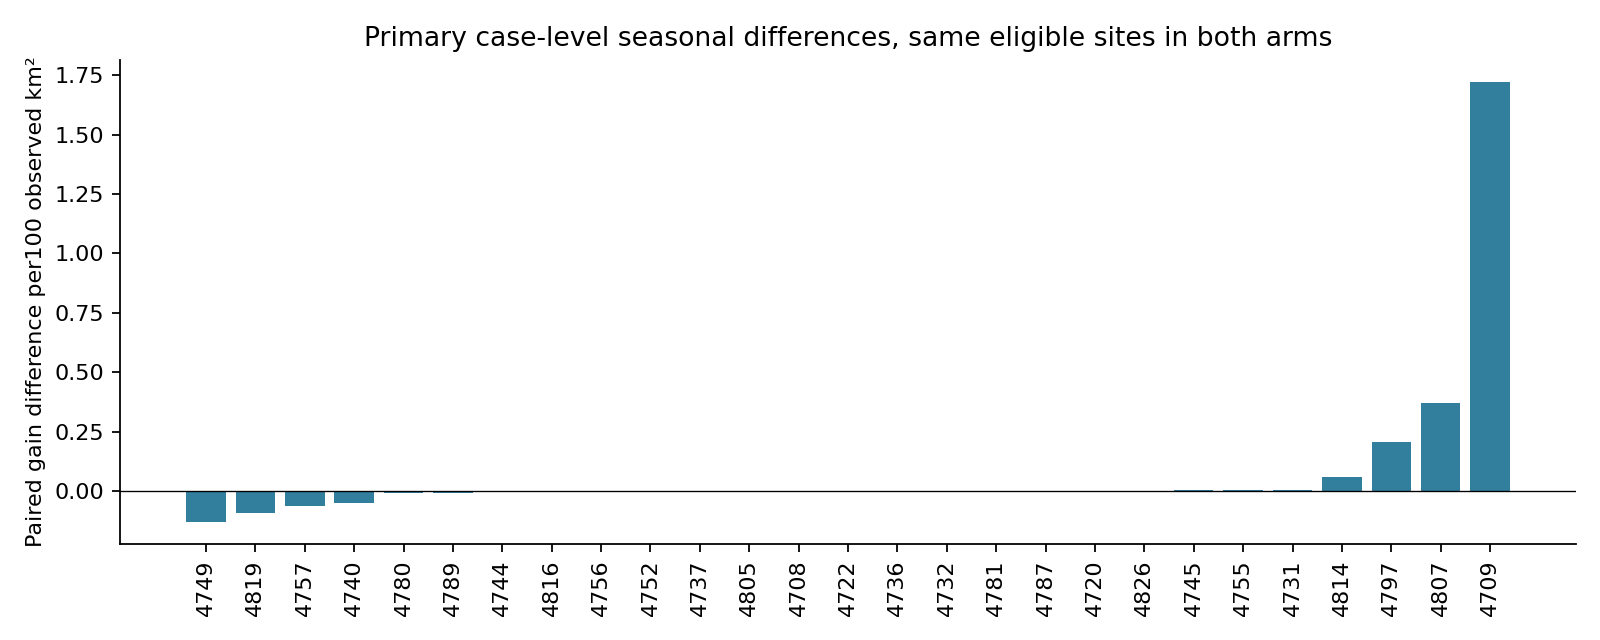

In [8]:
a=pd.read_csv(R/'phase50/aggregate_temporal_comparisons.csv')
display(a.query('denominator == "common_pixels" and threshold == .3')[['scheme','group','sites','cases','event_gain_per100','placebo_gain_per100','delta_gain_per100']])
display(Image(filename=str(R/'figures/phase50_placebo_sensitivity.png')))
display(Image(filename=str(R/'figures/phase50_case_differences.png')))

## 5. Geographic and independent-sensor evidence

NASA MODIS renders were obtained for six Minnesota windows on April12, April26 and May10,2023, chosen from regional NWS flood timing before inspecting the renders. The official legend marks gray as insufficient data; most inland renders are gray. Two added Houston County windows show the product’s flood color. These are coarse independently sensed classifier maps, not surveyed labels or a certified FEMA footprint. No precision, recall, IoU or false-positive rate is computed. Render transparency is not a dry-land label. Raw product/QA acquisition and contemporaneous version validation remain unresolved.

,sample_id,observation_date,status,displayed_flood_color_inside_polygon,displayed_insufficient_data_fraction_inside_polygon
0,4722_27001_1,2023-04-12,render_read_ok,False,0.972717
1,4722_27001_1,2023-04-26,render_read_ok,False,0.766907
2,4722_27001_1,2023-05-10,render_read_ok,False,1.000000
3,4722_27001_2,2023-04-12,render_read_ok,False,0.966744
4,4722_27001_2,2023-04-26,render_read_ok,False,1.000000
5,4722_27001_2,2023-05-10,render_read_ok,False,1.000000
6,4722_27001_3,2023-04-12,render_read_ok,False,1.000000
7,4722_27001_3,2023-04-26,render_read_ok,False,0.958547
8,4722_27001_3,2023-05-10,render_read_ok,False,1.000000
9,4722_27055_1,2023-04-12,render_read_ok,False,1.000000


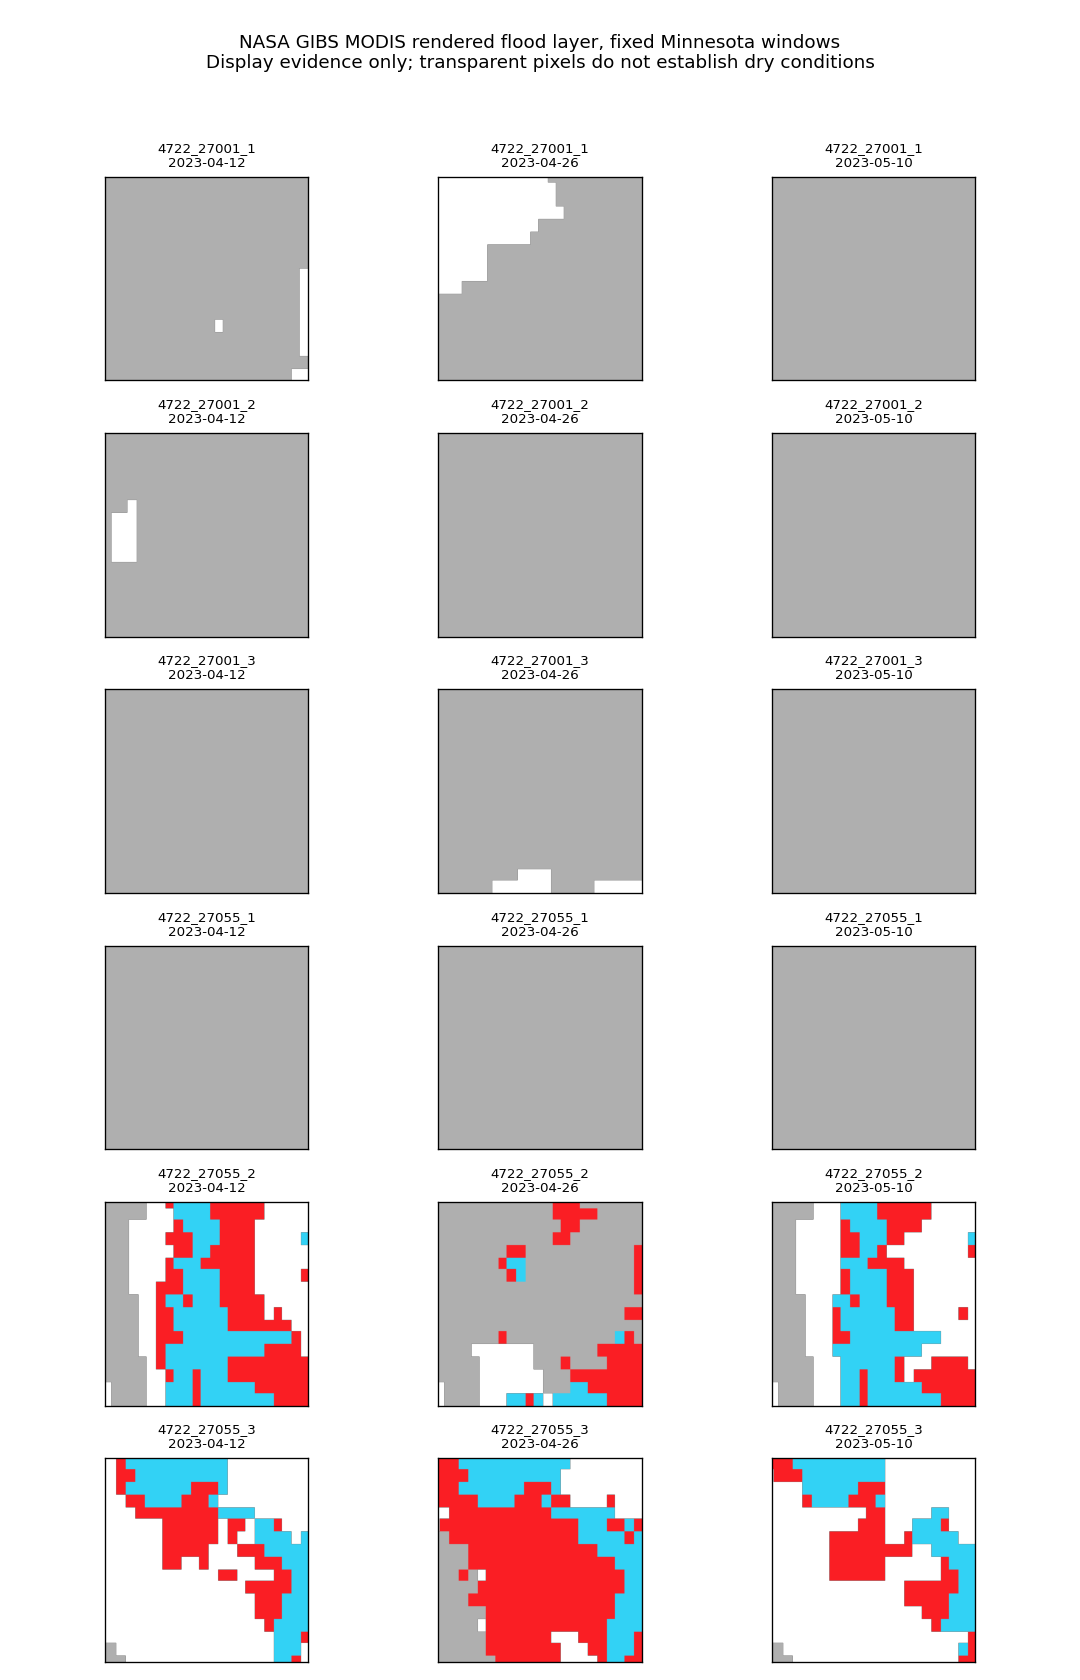

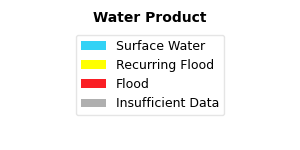

In [9]:
display(pd.read_csv(R/'flood_validation/nasa_mn_render_source_log.csv')[['sample_id','observation_date','status','displayed_flood_color_inside_polygon','displayed_insufficient_data_fraction_inside_polygon']])
display(Image(filename=str(R/'figures/six_sites_dated_maps.png')))
display(Image(filename=str(R/'flood_validation/MODIS_Flood_H.png')))

## 6. Other hazards and source limitations

The actual NOAA2024 archive contains wind and hail magnitudes and tornado EF/path fields. Winter-storm records lack equivalent numeric snow/ice fields in this archive, so event counts cannot substitute for intensity. NHC best tracks are retrospective estimates; -999 means missing, not a physical pressure or wind measurement. Eight earthquake regional queries succeeded, but date/box proximity is not event attribution. MTBS documentation is accessible; its advertised map service failed. No standalone model is fit to the eight earthquake records or nonexistent drought population.

In [10]:
display(pd.read_csv(R/'source_audit/noaa2024_physical_field_availability.csv'))
display(pd.read_csv(R/'source_audit/earthquake_query_coverage.csv'))
display(pd.read_csv(ROOT/'SOURCE_AND_FEATURE_MANIFEST.csv')[['feature','classification','T0_status','accepted_new_model']])

,source_event_type,records,classification,MAGNITUDE_nonmissing,MAGNITUDE_TYPE_nonmissing,TOR_F_SCALE_nonmissing,TOR_LENGTH_nonmissing,TOR_WIDTH_nonmissing,FLOOD_CAUSE_nonmissing
0,Astronomical Low Tide,17,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
1,Avalanche,26,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
2,Blizzard,332,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
3,Coastal Flood,382,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
4,Cold/Wind Chill,741,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
5,Debris Flow,171,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,171
6,Dense Fog,839,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
7,Drought,3473,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
8,Dust Devil,7,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0
9,Dust Storm,88,UNVERIFIED CANDIDATE for FEMA linkage,0,0,0,0,0,0


,disasterNumber,candidate_records,retrieval_ok
0,1911,15,True
1,4044,1,True
2,4042,1,True
3,4193,1,True
4,4413,17,True
5,4473,3,True
6,4548,3,True
7,4692,2,True


,feature,classification,T0_status,accepted_new_model
0,disasterNumber,UNVERIFIED CANDIDATE for prospective use,"identifier only; group events, not continuous ...",False
1,state,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False
2,declarationType,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False
3,declarationRequestNumber,UNVERIFIED CANDIDATE for prospective use,"identifier only; group events, not continuous ...",False
4,fyDeclared,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False
5,declarationDate,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False
6,incidentType,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False
7,incidentBeginDate,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False
8,incidentEndDate,UNVERIFIED CANDIDATE for prospective use,post-event/finalized feature: prohibit T0/T72 ...,False
9,designatedArea,UNVERIFIED CANDIDATE for prospective use,current metadata or engineered field: T0/T72 a...,False


## 7. Prediction and uncertainty synthesis

Previously reported Phase36 flood NOAA-density MAE was $355,021 against $537,057 FEMA-only on59 examined tests; Phase37 physical additions did not improve that density baseline. These are historical report values, not newly reproduced metrics. Existing chronological uncertainty experiments showed high pooled coverage while failing rare high-value disasters; CQR covered7/9 rare tests at90% nominal with mean interval width about$140.5M. Those tests are too few for reliable conditional coverage. No newly certified physical feature set or untouched cohort exists here, so no additional integration model is accepted.

In [11]:
display(pd.read_csv(ROOT/'MODEL_REGISTRY.csv')[['model_id','status','validation','run_id']])
print((R/'PROSPECTIVE_VALIDATION_PROTOCOL.md').read_text()[:2000])

,model_id,status,validation,run_id
0,TrackA_original_amount_stack,FROZEN historical version,912 fixed historical LFYO predictions recomput...,34796746603
1,TrackA_final_5014819,FROZEN user-accepted reconstruction,912 fixed historical LFYO predictions recomput...,41397678781
2,TrackB_Phase36_NOAA_density,EXPLORATORY; not replacement,"59 FY2021-24 earlier-year tests, extensively e...",41447664858
3,TrackB_Phase37_physical,NEGATIVE exploratory result vs density,same 59 floods; retrospective physical features,41483049801
4,TrackB_T72_NHC,EXPLORATORY; rare-tail failure,376 FY2019-24 earlier-year tests; contemporane...,41393614710
5,TrackB_CQR,"EXPLORATORY; extreme width, nine rare tests","536 train pre2019,68 calibration2019,308 test2...",41397857911


# Prospective validation protocol — design only, no new test outcomes

Freeze the code, features and policy before accessing future outcome labels.
The971 historical records and the 59 repeatedly examined flood tests are
exploratory material. Fiscal2025/2026 records are not automatically untouched,
finalized or comparable to the original funding snapshot.

1. Define a new cohort by an outcome-blind rule, preferably declarations issued
   after the frozen protocol date. A prospective FY 2027 cohort beginning after
   this freeze is possible; complete follow-up necessarily requires later data.
   Document partial-year selection. Include all eligible represented hazards,
   and preserve a separately reported non-Biological912-style scope definition.
2. Fix T0 to an authenticated declaration timestamp. If only a date exists,
   report timing ambiguity; do not silently interpret midnight as true issue time.
   Evaluate T+72 separately. Archive original county-designation versions.
3. Prespe

## 8. Allocation under uncertainty: simulation only

The original RL notebook rewards historical funding agreement; that is not a humanitarian utility measure. This separate experiment generates synthetic needs, vulnerability and budget releases with fixed seed20261117,300 episodes,8 arrivals and3 budget ratios. It compares five simultaneous and three sequential policies. The LP maximizes weighted delivered units subject to allocation bounds and cumulative cash constraints. A hindsight need-aware LP supplies a regret upper bound with the same sequential cash constraints. Fairness floors are an illustrative governance choice. The synthetic generator and policy definitions are fixed; no tuning against the simulated outcomes is used.

SIMULATION_COMPLETE 7200 policy evaluations; all cash and regret invariants passed



,setting,budget_ratio,policy,unmet_need_units,wasted_units,fulfilled_fraction,weighted_delivered,min_disaster_service,vulnerable_service_gap,budget_utilization,oracle_regret_units
3,sequential,0.7,equal_pacing,39.738928,6.441739,0.531615,58.540819,0.239919,0.007307,0.850340,23.850241
4,sequential,0.7,forecast_reserve,36.818335,6.194297,0.558292,62.860425,0.271694,0.024990,0.879436,19.530635
5,sequential,0.7,greedy_current,35.385460,10.740313,0.578513,64.974672,0.060354,0.007225,0.987608,17.416388
14,simultaneous,0.7,equal_capped,32.437420,8.671190,0.626279,69.645161,0.380968,0.014485,1.000000,14.851826
15,simultaneous,0.7,fairness_floor_LP,34.634679,10.868449,0.587483,68.717525,0.276908,0.284403,1.000000,15.779462
16,simultaneous,0.7,proportional_estimated_need,30.866259,7.100029,0.644887,71.905038,0.392232,0.022788,1.000000,12.591949
17,simultaneous,0.7,robust_upper_need,31.306046,7.539816,0.638049,71.826992,0.387192,0.081011,1.000000,12.669995
18,simultaneous,0.7,vulnerability_LP,36.478318,12.712088,0.558492,67.052930,0.033843,0.430701,1.000000,17.444057


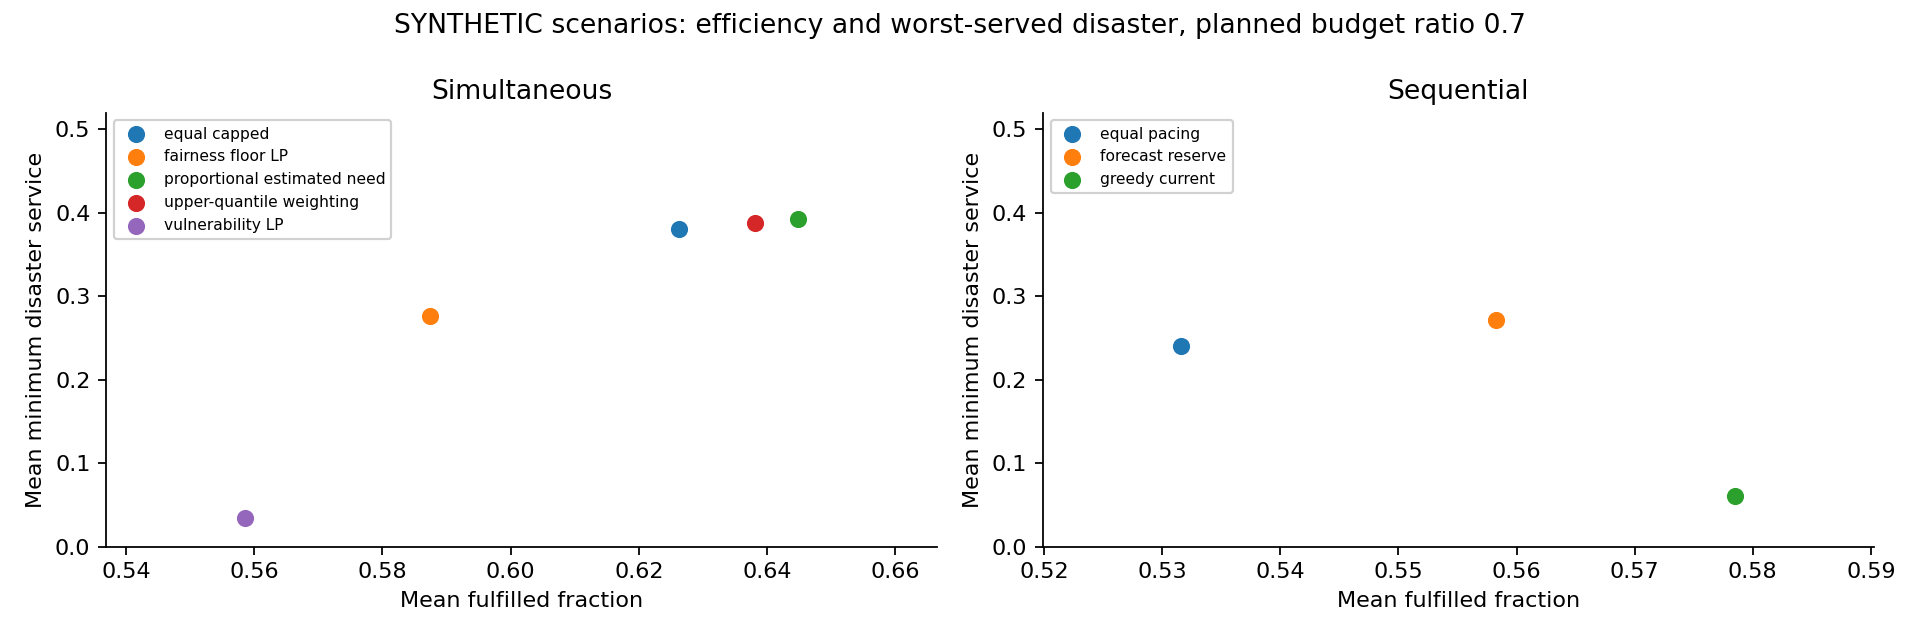

In [12]:
run=subprocess.run([sys.executable,str(ROOT/'analysis/continuation_allocation_simulation.py')],capture_output=True,text=True,timeout=120)
assert run.returncode==0,run.stderr
print(run.stdout)
for name in ['simulation_policy_summary.csv','simulation_episode_metrics.csv']:
    pd.testing.assert_frame_equal(pd.read_csv(R/'allocation'/name),pd.read_csv(ROOT/'work/allocation'/name),check_exact=False,rtol=1e-9,atol=1e-9)
display(pd.read_csv(R/'allocation/simulation_policy_summary.csv').query('budget_ratio==.7'))
display(Image(filename=str(R/'figures/simulation_efficiency_fairness.png')))

## 9. Human decision-support demonstration and scientific conclusion

The demonstration identifies actual source evidence, verified historical case predictions, insufficient interval evidence and independently synthetic allocation examples. It abstains instead of fabricating a case funding estimate. Policy choices and final allocation remain with human decision-makers. Read the final conclusion for completed work, genuine blockers and exact next steps.

In [13]:
run=subprocess.run([sys.executable,str(ROOT/'analysis/research_decision_support_demo.py')],capture_output=True,text=True,timeout=60)
assert run.returncode==0,run.stderr
demo=json.loads((ROOT/'work/decision_support_demo.json').read_text())
display(demo['historical_funding']);display(demo['uncertainty'])
display(Markdown((R/'FINAL_CONCLUSION.md').read_text()))

{'status': 'exact frozen artifact verified; historical case outputs available',
 'aggregate_reported_benchmark': {'n': 912,
  'router_correct': 830,
  'MAE_USD': 5014819.011614494},
 'target': 'historical obligations, not humanitarian need',
 'validation': 'LFYO retrospective, future years may enter training',
 'verified_rows': 912,
 'historical_case_4722': [{'disasterNumber': 4722,
   'target': 1243478.26,
   'actual_band': '1M-50M',
   'router_pred': '1M-50M',
   'challenger_stack_prediction': 1244659.8883010906}]}

{'status': 'human review required',
 'reason': 'catastrophic calibration support insufficient; no valid event-specific interval recovered'}

# Bounded scientific conclusion and completion status

The accepted historical Track A benchmark is preserved. This continuation has
**not established a fully validated operational multi-hazard allocation model**
or a validated improvement over Track A. It has completed the interrupted Phase 50
temporal placebo analysis using real satellite pixels, exposed a material metadata
error and strong spatial sensitivity, and implemented reproducible evidence and
allocation audits. Unsupported model replacement would overstate the evidence.

## Results supported by executed work

- The workbook contains 971 unique disaster records,912 non-Biological records,
  and 20 incident-type labels. The largest groups are430 severe storms,198 floods,
  108 hurricanes and 59 Biological records. There are33 fires,27 tornadoes and 8
  earthquakes. There are no Drought records. One negative net-funding target is
  retained in the workbook; the original band function clamps it to zero.
- The exact original 912-case prediction archive was recovered through the
  GitHub connector and its ZIP checksum matches GitHub's digest. Recomputing
  those fixed predictions gives 830/912 routing, MAE $5,014,819.011614494,
  RMSE $64,653,747.252143376 and R² 0.8867765710842239. Balanced accuracy is
  0.895451 and macro F1 is 0.878561. These remain historical LFYO results,
  not a new independent or prospective evaluation. Complete per-case predictions,
  confusion matrices, hazard/year/band errors and influence tables are saved.
- All342 files tracked at the starting research commit retain their original
  SHA256 checksums. Main has not been modified or merged.
- Phase 50 completed289 planned monthly raster reads successfully over 67 fixed
  windows:63 anchor keys and 4 additional Minnesota keys. The source edition is
  JRC v1.5 for2022–2024. The primary seasonal comparison uses44 sufficiently
  observable anchors covering27/36 eligible disasters; not all63 anchors qualify.
- At30% common observability, the seasonal primary event-minus-placebo gain is
  **0.053073 km² per100 observed km²**. Event and placebo gain rates are0.080857
  and 0.027784. Excluding Minnesota DR 4722 yields0.054403. Adding its four extra
  sites raises the pooled difference to**0.687342**, with 46 qualifying sites.
  This large dependence on site placement rejects a stable disaster-wide
  interpretation. The primary case-level median is zero; see the actual case
  table for the signed differences and the coverage sensitivity tables.
- The2024 interannual primary comparison covers17 sites and 11 disasters and
  yields0.086369 km² excess gain per100 common observed km². Neither placebo
  design identifies known flood-free truth, so neither estimates a false-positive
  rate or causal disaster effect.
- DR 4816 is dated2024-08-22 in the workbook but2024-06-22 in current official
  FEMA metadata. Using June reproduces its historical raster log. The original
  workbook was not changed. All65 sites with usable historical log observations
  now reproduce the logged observability and rounded gain; the two Alaska
  anchors have no comparable successful entry in that pre-correction log.
- Original Phase48, Phase49 and Phase49b ZIPs were subsequently recovered and
  byte-verified. All 187 reconstructed geometries match exactly; all 63 original
  anchor coordinates agree; and all 67 Phase50 integer water-gain counts and
  event observation fractions match the corrected original CSVs, including Alaska.
  The Alaska-only merge verifies 187 sites, 374 comparisons and 561 monthly rows.
- Eighteen NASA MODIS rendered maps were obtained for the exact six Minnesota
  windows on2023-04-12,2023-04-26 and 2023-05-10. Some added Houston County
  windows show the product’s flood color. Many inland views show insufficient
  data. These maps strengthen sensor-level context, but they are coarse rendered
  classifications without raw QA or independent surveyed labels. No flood IoU,
  precision, recall, certified footprint or footprint-derived exposure is claimed.
- An official2024 NOAA storm archive, an official Atlantic HURDAT2 archive and
  eight USGS earthquake-query responses were retrieved. They establish useful
  physical-field availability, not verified disaster attribution. MTBS catalog
  documentation was retrieved; its advertised map service returned503. No
  accepted model consumes the unverified candidate features.
- A separate synthetic allocation experiment executed300 episodes,8 arrivals,
  3 budget ratios and 8 policy configurations:7,200 policy evaluations. All
  cumulative cash constraints and hindsight-oracle regret bounds passed. At
  planned budget ratio 0.7, sequential greedy allocation has mean fulfilled
  fraction0.5785 and mean minimum-disaster service0.0604; forecast reserve has
  0.5583 and 0.2717. These are trade-offs under one synthetic generator, not real
  humanitarian outcomes. Historical funding was not used as need.

## Research decisions

Retain Track A as the frozen **retrospective accounting-prediction benchmark**.
Keep physical-evidence enrichment separate until event attribution, source timing,
coverage and independent validation are established. Do not train another funding
model merely to optimize the already examined59 flood tests. Existing comparisons
and uncertainty studies are preserved as exploratory historical evidence.

The final defensible research architecture separates: source evidence and quality
gates; historical funding prediction; prediction uncertainty and abstention; an
independent need/utility definition; constrained allocation; human review. Its
components have different validation levels. The supplied demonstration runs this
separation and abstains when exact case predictions or credible need inputs are
missing. It is not an operational deployment.

The original reconstruction uses LFYO, which can train on future fiscal years.
New operational comparisons must use strictly earlier training years and
training-only nested selection. Current metadata snapshots do not establish
historical T0/T+72 availability. Excellent retrospective R² cannot repair that
limitation. The handoff’s shorthand about upper-band median specialists is also
incomplete: source code and reconstruction evidence retain a50–200M hybrid and
upper-band specialists. They have not been overwritten with reconstructed medians.

Previously reported interval results show the difference between pooled coverage
and catastrophic reliability. CQR reported7/9 high-value cases covered at90%
nominal, with mean interval width about$140.5M. That is too little tail support
and too much variability for a reliable catastrophic allocation guarantee.
Those are separate Track B models, not intervals fitted around the accepted
Track A predictions. No new interval claim is made here.

## What remains incomplete and why

1. Complete validated multi-hazard physical/exposure dataset: physical sources
   were retrieved in bounded pilots, but broad event linkage, perimeters,
   hydrological relevance, population/building vintage and uncertainty remain
   unverified. Thirty-three fire records do not justify claiming absent wildfire
   data; acquisition and matching remain incomplete, not scientifically impossible.
2. Independent flood labels and raw MODIS historical product QA: rendered maps
   are accessible, but survey truth and raw-product ingestion were not completed.
   Current NASA documentation advertises historical products; do not claim no
   archive exists merely because older documentation described rolling retention.
3. A new untouched evaluation population and comparable finalized targets:
   no such targets were selected or inspected here. A prospective protocol is
   supplied; realized future outcomes cannot be generated within this session.
4. New integration/ensemble selection, measurement-uncertainty propagation,
   real-need allocation validation and reliable rare-event intervals: these
   depend on the preceding data and validation gates. They were not executed
   and must not appear as successful results in a thesis.
5. Comprehensive novelty review and full text verification of all literature:
   a bounded primary-source search was performed. Existing surface-water and
   conformal methods are not novel. No “first” or globally novel framework claim
   is established. A publisher search lead on disaster DSS remains incompletely
   verified and is excluded from a formal verified bibliography.

These gaps mean the full requested thesis research objective remains incomplete.
This report is a substantive, recoverable research checkpoint and a defensible
conclusion about the available evidence, not a declaration that all objectives
have been met. Prediction and geospatial archive access is resolved through the
connector despite persistent CLI403. Separate trained-model weights were not
verified; original training procedures remain preserved. A descriptive fiscal-year
block bootstrap of accepted-minus-original historical MAE gives -$116,541,
with percentile interval [-$301,156, +$28,174]; it crosses zero and is not an
independent validation claim. The next work should ingest raw flood QA and certify
hazard linkage before introducing more models. See STATUS.md and TECHNICAL_GUIDE.md
for exact commands and remaining gates.


## 10. Provenance and references

Source checksums apply to the exact saved bytes identified in each record. Cropped JRC array checksums do not identify entire remote tiles. Unknown release dates and licensing details remain explicitly unknown. References verified only at abstract/metadata level are labelled accordingly. A comprehensive novelty claim is not established.

In [14]:
display(pd.read_csv(ROOT/'REFERENCE_REGISTRY.csv'))
print('Source-registry records:',len(pd.read_csv(ROOT/'DATA_SOURCE_REGISTRY.csv')))
git_result=subprocess.run(['git','rev-parse','HEAD'],cwd=ROOT,capture_output=True,text=True)
print('Source checkpoint:',git_result.stdout.strip() if git_result.returncode==0 else 'archive snapshot without .git; see the verified repository release')

,id,title,authors,year,url,doi,verification,claim_scope,verification_date
0,Pekel2016,High-resolution mapping of global surface wate...,Pekel; Cottam; Gorelick; Belward,2016.0,https://www.nature.com/articles/nature20584,10.1038/nature20584,original publisher search metadata and JRC ins...,original surface-water mapping method; not val...,2026-11-17
1,Romano2019,Conformalized Quantile Regression,Romano; Patterson; Candes,2019.0,https://proceedings.neurips.cc/paper_files/pap...,NaN,original NeurIPS proceedings abstract and auth...,CQR method already exists; not proof of validi...,2026-11-17
2,NASA_LANCE,Flood Location Observation and Overview Dashboard,NASA LANCE,2026.0,https://lance.modaps.eosdis.nasa.gov/flood/,NaN,official page retrieved and checksummed,MODIS/VIIRS flood products and version chronol...,2026-11-17
3,NWS2023,Mississippi River Flood of 2023,National Weather Service La Crosse,2023.0,https://www.weather.gov/arx/flood2023,NaN,official page retrieved; hydrographs and dated...,regional April-May2023 flooding and gauge-stag...,2026-11-17
4,Slayback2023,Update on LANCE Flood Product (MCDWD),Slayback; Davies; Devadiga; Landis; Shrestha,2023.0,https://www.ssec.wisc.edu/meetings/wp-content/...,NaN,"original meeting PDF downloaded; title, presen...",2023 sensor product and threshold/masking limi...,2026-11-17
5,ReliefDSS_prior_art,A decision support tool for allocating tempora...,not independently verified,NaN,https://www.sciencedirect.com/science/article/...,NaN,publisher search excerpt found; direct full pa...,novelty search lead only; no detailed performa...,2026-11-17


Source-registry records: 333
Source checkpoint: archive snapshot without .git; see the verified repository release
